# Amazon Beauty Sentiment Analysis - DistilRoBERTa-base (Fine-Tuning)

Standalone companion notebook to the classical-ML notebook (Logistic Regression / Linear SVC / Complement Naive Bayes). Built for a **perfectly fair, scientific comparison**:

1. **Identical experimental setup** -- same raw data load/merge/clean pipeline, same `SAMPLE_SIZE=100_000`, same `RANDOM_STATE=42`, same stratified 70/15/15 train/val/test split, same 5-class -> 3-class sentiment mapping, same `CLASS_LABELS` order. Given the same `RANDOM_STATE`, `train_df` / `val_df` / `test_df` here contain the exact same rows as in the classical-ML notebook.
2. **Handling class imbalance** -- the classical notebook used `class_weight="balanced"` inside each sklearn estimator; here the same balanced weighting formula is computed and injected into a class-weighted `CrossEntropyLoss` via a custom `Trainer`, the direct architectural equivalent for a transformer.
3. **Evaluation metrics** -- identical `classification_report`, confusion matrices (raw + row-normalized), and macro-F1 / weighted-F1 / minority-class-F1, computed with the same `CLASS_LABELS` and the same `MINORITY_CLASS` definition as every other model in this project. Also includes a minority-class threshold-tuning step mirroring Section 14.3 of the classical notebook.
4. **Output format** -- produces a `master_df_distilroberta` with the exact same schema (`model`, `accuracy`, `macro_f1`, `weighted_f1`, `{MINORITY_CLASS}_f1`) as the classical notebook's `master_df`, and saves it (plus raw predictions) to disk so it can be concatenated directly for a full 4-way comparison.

GPU strongly recommended for the training section.

## 1. Install & import required libraries

In [ ]:
# Install libraries (only needed once per environment)
!pip install datasets==2.20.0 -q
!pip install transformers==4.44.2 accelerate evaluate -q
!pip install scikit-learn matplotlib seaborn -q


  error: subprocess-exited-with-error
  
  × Building wheel for tokenizers (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [135 lines of output]
      Rust not found, installing into a temporary directory
      Python reports SOABI: cp313-win_amd64
      Computed rustc target triple: x86_64-pc-windows-msvc
      Installation directory: C:\Users\S-GF-L1-D10\AppData\Local\puccinialin\puccinialin\Cache
      Rustup already downloaded
      Installing rust to C:\Users\S-GF-L1-D10\AppData\Local\puccinialin\puccinialin\Cache\rustup
      warn: It looks like you have an existing rustup settings file at:
      warn: C:\Users\S-GF-L1-D10\AppData\Local\puccinialin\puccinialin\Cache\rustup\settings.toml
      warn: Rustup will install the default toolchain as specified in the settings file,
      warn: instead of the one inferred from the default host triple.
      info: profile set to minimal
      info: setting default host triple to x86_64-pc-windows-msvc
      warn: Updating

In [ ]:
import re
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset, Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix, f1_score,
    ConfusionMatrixDisplay, precision_recall_curve, calibration_curve,
)
from sklearn.utils.class_weight import compute_class_weight

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    set_seed,
)

RANDOM_STATE = 42                         # identical to the classical-ML notebook
pd.set_option("display.max_columns", None)

# ---------------------------------------------------------------------------
# torch/np seeds alone do NOT cover everything HF's Trainer seeds internally
# (dropout mask initialization order, internal data-sampler shuffling, etc).
# transformers.set_seed() seeds python/random, numpy, torch (CPU+CUDA) AND
# a few HF-internal RNGs in one call - use it as the single source of truth.
# ---------------------------------------------------------------------------
set_seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", DEVICE)

# fp16 mixed precision only has an effect on CUDA; on CPU-only runtimes
# TrainingArguments(fp16=True) is silently a no-op, which can be mistaken
# for a successful mixed-precision run. Flag this explicitly up front.
if DEVICE == "cpu":
    print("WARNING: No GPU detected. fp16 mixed precision will be disabled "
          "regardless of the fp16 flag passed to TrainingArguments, and "
          "training will be substantially slower. Consider using the "
          "MAX_TRAIN_SAMPLES smoke-test flag (Section 10) to validate the "
          "pipeline before committing to a full run.")


c:\Users\S-GF-L1-D10\Desktop\NileGuard\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cuda


## 2. Load the reviews dataset (All Beauty)

Identical source and split as the classical-ML notebook.

In [ ]:
dataset = load_dataset(
    "McAuley-Lab/Amazon-Reviews-2023", "raw_review_All_Beauty", trust_remote_code=True
)
df = pd.DataFrame(dataset["full"])
print("Reviews shape:", df.shape)
df.head(3)


Reviews shape: (701528, 10)


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,5.0,Such a lovely scent but not overpowering.,This spray is really nice. It smells really go...,[],B00YQ6X8EO,B00YQ6X8EO,AGKHLEW2SOWHNMFQIJGBECAF7INQ,1588687728923,0,True
1,4.0,Works great but smells a little weird.,"This product does what I need it to do, I just...",[],B081TJ8YS3,B081TJ8YS3,AGKHLEW2SOWHNMFQIJGBECAF7INQ,1588615855070,1,True
2,5.0,Yes!,"Smells good, feels great!",[],B07PNNCSP9,B097R46CSY,AE74DYR3QUGVPZJ3P7RFWBGIX7XQ,1589665266052,2,True


## 3. Load the metadata dataset (product info) and merge

In [ ]:
dataset_meta = load_dataset(
    "McAuley-Lab/Amazon-Reviews-2023", "raw_meta_All_Beauty", trust_remote_code=True
)
df_meta = pd.DataFrame(dataset_meta["full"])
print("Metadata shape (before dedup):", df_meta.shape)

# Same fix as the classical-ML notebook: dedup on parent_asin before merging
# to avoid silently inflating the dataset via a many-to-one join.
df_meta = df_meta.drop_duplicates(subset="parent_asin", keep="first")
print("Metadata shape (after dedup):", df_meta.shape)


Metadata shape (before dedup): (112590, 16)
Metadata shape (after dedup): (112590, 16)


In [ ]:
merged_df = pd.merge(df, df_meta, on="parent_asin", how="left")
print("Merged shape:", merged_df.shape)
assert merged_df.shape[0] == df.shape[0], "Merge produced extra rows - check for duplicate keys."

sentiment_mapping = {
    1.0: "Very Negative", 2.0: "Negative", 3.0: "Neutral",
    4.0: "Positive", 5.0: "Very Positive",
}
merged_df["sentiment"] = merged_df["rating"].map(sentiment_mapping)
merged_df["sentiment"].value_counts()


Merged shape: (701528, 25)


sentiment
Very Positive    420726
Very Negative    102080
Positive          79381
Neutral           56307
Negative          43034
Name: count, dtype: int64

## 4. Cleaning the merged dataframe

Identical columns dropped and identical filtering rules as the classical-ML notebook.

In [ ]:
merged_df["review"] = (
    merged_df["title_x"].fillna("").astype(str) + " " + merged_df["text"].fillna("").astype(str)
)

columns_to_drop = [
    "images_x", "asin", "parent_asin", "user_id", "timestamp", "images_y",
    "videos", "categories", "bought_together", "subtitle", "author", "title_x", "text",
]
merged_df.drop(columns=columns_to_drop, inplace=True)

merged_df = merged_df[
    merged_df["review"].notna() & (merged_df["review"].str.strip() != "")
].copy()
merged_df.drop_duplicates(subset=["review"], inplace=True)
merged_df = merged_df[merged_df["review"].str.split().str.len() >= 3].copy()
merged_df.drop(columns=["store"], inplace=True)
merged_df["price"] = pd.to_numeric(merged_df["price"], errors="coerce")
merged_df.drop(columns=["price"], inplace=True)

print(merged_df.columns.tolist())
print(merged_df.shape)


['rating', 'helpful_vote', 'verified_purchase', 'main_category', 'title_y', 'average_rating', 'rating_number', 'features', 'description', 'details', 'sentiment', 'review']
(668848, 12)


## 5. Draw an unbiased (stratified) sample + 6. Train/Val/Test split

Same `SAMPLE_SIZE`, same stratify column, same `RANDOM_STATE`, same two-step
70/15/15 split as every other model in this project -- `train_df` / `val_df`
/ `test_df` contain the exact same rows here as in the classical-ML
notebook.

In [ ]:
SAMPLE_SIZE = 100_000  # identical to the classical-ML notebook

sample_df, _ = train_test_split(
    merged_df, train_size=SAMPLE_SIZE, stratify=merged_df["sentiment"], random_state=RANDOM_STATE
)

train_df, temp_df = train_test_split(
    sample_df, test_size=0.30, stratify=sample_df["sentiment"], random_state=RANDOM_STATE
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["sentiment"], random_state=RANDOM_STATE
)

print("Train:", train_df.shape, "| Val:", val_df.shape, "| Test:", test_df.shape)


Train: (70000, 12) | Val: (15000, 12) | Test: (15000, 12)


## 7. Text preprocessing - Transformer pipeline

Only the shared LIGHT cleaning is used (URLs/HTML stripped, whitespace
collapsed) -- casing and punctuation preserved, exactly as Section 8.3 of
the classical-ML notebook specifies for transformer models. No
lowercasing / stopword removal / lemmatization here (that's the TF-IDF-only
pipeline and would strip signal a subword tokenizer can use).

In [ ]:
def basic_clean(text):
    """Light cleaning shared across every model family in this project:
    remove links, HTML tags, and collapse extra whitespace."""
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

for split_df in [train_df, val_df, test_df]:
    split_df["review_basic"] = split_df["review"].apply(basic_clean)
    split_df["review_transformer"] = split_df["review_basic"]

train_df[["review", "review_transformer"]].head(3)


,review,review_transformer
328723,Good Purchase Is a Christmas gift. Don't know...,Good Purchase Is a Christmas gift. Don't know ...
246525,Saved my mouth when I didn't yet have insuranc...,Saved my mouth when I didn't yet have insuranc...
606291,Great product Really makes a difference in my ...,Great product Really makes a difference in my ...


## 8. Class Mapping (5 Classes -> 3 Classes)

Identical mapping and identical fixed `CLASS_LABELS` order to the classical-ML notebook.

In [ ]:
sentiment_map_5_to_3 = {
    "Very Negative": "Negative", "Negative": "Negative", "Neutral": "Neutral",
    "Positive": "Positive", "Very Positive": "Positive",
}
for split_df in [train_df, val_df, test_df]:
    split_df["sentiment_3class"] = split_df["sentiment"].map(sentiment_map_5_to_3)

CLASS_LABELS = ["Negative", "Neutral", "Positive"]          # fixed order used everywhere
label2id = {label: i for i, label in enumerate(CLASS_LABELS)}
id2label = {i: label for label, i in label2id.items()}

y_train = train_df["sentiment_3class"]
y_val = val_df["sentiment_3class"]
y_test = test_df["sentiment_3class"]

for split_df in [train_df, val_df, test_df]:
    split_df["label"] = split_df["sentiment_3class"].map(label2id)

MINORITY_CLASS = y_train.value_counts().idxmin()
print("Minority class:", MINORITY_CLASS)
print(train_df["sentiment_3class"].value_counts())


Minority class: Neutral
sentiment_3class
Positive    49376
Negative    14872
Neutral      5752
Name: count, dtype: int64


## 9. Handling Class Imbalance

The classical models used `class_weight="balanced"` inside the estimator.
DistilRoBERTa has no such argument, so we compute the SAME "balanced"
weighting scheme -- `weight(c) = n_samples / (n_classes * n_samples_in_class)`
-- and inject it into a class-weighted `CrossEntropyLoss` via a custom
`Trainer`. This is the direct architectural equivalent of
`class_weight="balanced"`, applied at the loss level instead of the
sklearn-estimator level. (TF-IDF-space SMOTE / text-augmentation
oversampling don't have a clean analogue for token-level transformer
input, so class-weighted loss is the fair apples-to-apples imbalance
strategy here.)

In [ ]:
class_weights_arr = compute_class_weight(
    class_weight="balanced", classes=np.array(CLASS_LABELS), y=y_train
)
class_weight_dict = dict(zip(CLASS_LABELS, class_weights_arr))
print("Computed class weights (same 'balanced' formula as the classical-ML notebook):")
for label, weight in class_weight_dict.items():
    print(f"  {label:10s}: {weight:.3f}")

class_weights_tensor = torch.tensor(
    [class_weight_dict[CLASS_LABELS[i]] for i in range(len(CLASS_LABELS))], dtype=torch.float
).to(DEVICE)


Computed class weights (same 'balanced' formula as the classical-ML notebook):
  Negative  : 1.569
  Neutral   : 4.057
  Positive  : 0.473


## 10. Model + Tokenizer Setup (distilroberta-base)

### 10a. Verifying `MAX_LENGTH` (Truncation Check)

`MAX_LENGTH=256` was previously asserted based on the EDA review-length histogram, but never directly verified against the transformer's own tokenizer (word-level length and subword/token-level length are not the same thing -- lemmatization-free transformer text can tokenize to more subwords per word than expected). We tokenize a sample **without truncation** first and measure what fraction of reviews would actually be cut off at 256 tokens, since silent truncation of a meaningful fraction of reviews would be losing real sentiment signal (e.g. a caveat buried at the end of a long review).

In [ ]:
MODEL_NAME = "distilroberta-base"
MAX_LENGTH = 256  # candidate value, verified below before committing to it

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# ---------------------------------------------------------------------------
# Tokenize a sample of train reviews WITHOUT truncation to see real token
# lengths, then compute what % would be truncated at MAX_LENGTH=256.
# ---------------------------------------------------------------------------
_check_sample = train_df["review_transformer"].sample(
    n=min(5000, len(train_df)), random_state=RANDOM_STATE
)
_token_lengths = [
    len(tokenizer.encode(t, truncation=False)) for t in _check_sample
]
_token_lengths = np.array(_token_lengths)

pct_truncated = (_token_lengths > MAX_LENGTH).mean() * 100
print(f"Token length stats on a {len(_check_sample)}-review sample:")
print(f"  mean={_token_lengths.mean():.1f}  median={np.median(_token_lengths):.0f}  "
      f"p95={np.percentile(_token_lengths, 95):.0f}  max={_token_lengths.max()}")
print(f"Reviews exceeding MAX_LENGTH={MAX_LENGTH} tokens: {pct_truncated:.2f}%")

plt.figure(figsize=(7, 4))
plt.hist(_token_lengths, bins=50)
plt.axvline(MAX_LENGTH, color="red", linestyle="--", label=f"MAX_LENGTH={MAX_LENGTH}")
plt.xlabel("Token count (untruncated)")
plt.ylabel("Number of reviews")
plt.title("Token length distribution vs MAX_LENGTH")
plt.legend()
plt.tight_layout()
plt.show()

if pct_truncated > 5:
    print(f"NOTE: >5% of reviews are being truncated ({pct_truncated:.2f}%). "
          f"Consider raising MAX_LENGTH if compute budget allows - truncated "
          f"content may be dropping real signal (e.g. a caveat at the end of "
          f"an otherwise positive review).")
else:
    print(f"MAX_LENGTH={MAX_LENGTH} covers the large majority of reviews "
          f"({100 - pct_truncated:.2f}%); truncation loss is minimal.")


### 10b. Smoke-Test Flag (`MAX_TRAIN_SAMPLES`)

Set `MAX_TRAIN_SAMPLES` to a small integer (e.g. 2000) to subsample the training set and quickly validate the entire pipeline end-to-end (tokenization, training loop, evaluation) on CPU or a small GPU before committing to a full, multi-hour run. Set to `None` for the real run.

In [ ]:
MAX_TRAIN_SAMPLES = None  # e.g. 2000 for a fast CPU smoke-test; None = full training set

if MAX_TRAIN_SAMPLES is not None:
    print(f"SMOKE-TEST MODE: subsampling train_df to {MAX_TRAIN_SAMPLES} rows "
          f"(was {len(train_df)}). Set MAX_TRAIN_SAMPLES = None for the real run.")
    train_df_active = train_df.sample(
        n=min(MAX_TRAIN_SAMPLES, len(train_df)), random_state=RANDOM_STATE
    ).reset_index(drop=True)
else:
    train_df_active = train_df


In [ ]:
def tokenize_fn(batch):
    return tokenizer(batch["review_transformer"], truncation=True, max_length=MAX_LENGTH)

train_ds = Dataset.from_pandas(train_df_active[["review_transformer", "label"]].reset_index(drop=True))
val_ds = Dataset.from_pandas(val_df[["review_transformer", "label"]].reset_index(drop=True))
test_ds = Dataset.from_pandas(test_df[["review_transformer", "label"]].reset_index(drop=True))

# num_proc parallelizes tokenization across CPU cores - meaningful speedup at
# 70K+ rows. load_from_cache_file=False forces re-tokenization if MAX_LENGTH
# or train_df_active changes between runs (avoids stale-cache bugs).
import os
_num_proc = max(1, os.cpu_count() - 1)

train_ds = train_ds.map(tokenize_fn, batched=True, num_proc=_num_proc, load_from_cache_file=False)
val_ds = val_ds.map(tokenize_fn, batched=True, num_proc=_num_proc, load_from_cache_file=False)
test_ds = test_ds.map(tokenize_fn, batched=True, num_proc=_num_proc, load_from_cache_file=False)

# ---------------------------------------------------------------------------
# Verify tokenization did not silently drop any rows (rare but possible with
# .map() + multiprocessing if a batch raises and gets silently skipped by a
# misconfigured error handler).
# ---------------------------------------------------------------------------
assert len(train_ds) == len(train_df_active), (
    f"Row count mismatch after tokenization: train_ds={len(train_ds)} vs "
    f"train_df_active={len(train_df_active)}"
)
assert len(val_ds) == len(val_df), (
    f"Row count mismatch after tokenization: val_ds={len(val_ds)} vs val_df={len(val_df)}"
)
assert len(test_ds) == len(test_df), (
    f"Row count mismatch after tokenization: test_ds={len(test_ds)} vs test_df={len(test_df)}"
)
print("Row-count check passed: train/val/test dataset sizes match their source dataframes.")

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(CLASS_LABELS), id2label=id2label, label2id=label2id,
).to(DEVICE)


Loading weights: 100%|██████████| 101/101 [00:00<00:00, 14182.75it/s]
[transformers] RobertaForSequenceClassification LOAD REPORT from: distilroberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
# Class-weighted Trainer -- implements the Section 9 imbalance handling at
# the loss level (see note above)
class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fct = torch.nn.CrossEntropyLoss(weight=class_weights_tensor)
        loss = loss_fct(logits, labels)
        return (loss, outputs) if return_outputs else loss


## 11. Model Training

In [ ]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    pred_labels = [CLASS_LABELS[p] for p in preds]
    true_labels = [CLASS_LABELS[l] for l in labels]
    return {
        "accuracy": (np.array(pred_labels) == np.array(true_labels)).mean(),
        "macro_f1": f1_score(true_labels, pred_labels, labels=CLASS_LABELS, average="macro"),
        "weighted_f1": f1_score(true_labels, pred_labels, labels=CLASS_LABELS, average="weighted"),
    }

training_args = TrainingArguments(
    output_dir="./distilroberta_sentiment",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    logging_steps=100,
    seed=RANDOM_STATE,
    report_to="none",
    fp16=torch.cuda.is_available(),
)

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,  # Replaced tokenizer=tokenizer
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
)

trainer.train()


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,0.462888,0.461062,0.893133,0.783576,0.900248
2,0.383270,0.551557,0.899733,0.785650,0.904523
3,0.339388,0.613186,0.903600,0.790512,0.907543


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.61it/s]


TrainOutput(global_step=13125, training_loss=0.42910844294230144, metrics={'train_runtime': 1144.4246, 'train_samples_per_second': 183.498, 'train_steps_per_second': 11.469, 'total_flos': 8812488756921120.0, 'train_loss': 0.42910844294230144, 'epoch': 3.0})

### 11a. Training / Validation Loss Curves

Plotting train-loss (logged every `logging_steps`) against eval-loss (logged every epoch) from `trainer.state.log_history` makes overfitting visible directly -- if eval-loss starts rising while train-loss keeps falling, that's the epoch to have stopped at (which is also what `EarlyStoppingCallback` is protecting against, but a plot makes it legible rather than implicit).

In [ ]:
log_history = trainer.state.log_history

train_steps = [e["step"] for e in log_history if "loss" in e]
train_losses = [e["loss"] for e in log_history if "loss" in e]

eval_epochs = [e["epoch"] for e in log_history if "eval_loss" in e]
eval_losses = [e["eval_loss"] for e in log_history if "eval_loss" in e]

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(train_steps, train_losses, label="Train loss", color="#4C72B0", alpha=0.7)
ax1.set_xlabel("Training step")
ax1.set_ylabel("Train loss")

ax2 = ax1.twiny()
ax2.plot(
    [e * (train_steps[-1] / eval_epochs[-1]) for e in eval_epochs],
    eval_losses, label="Eval loss", color="#C44E52", marker="o",
)
ax2.set_xticks([])

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")
plt.title("Training vs Validation Loss - DistilRoBERTa fine-tuning")
plt.tight_layout()
plt.show()

print("Eval loss by epoch:", list(zip([round(e, 1) for e in eval_epochs], [round(l, 4) for l in eval_losses])))
if len(eval_losses) >= 2 and eval_losses[-1] > eval_losses[-2]:
    print("NOTE: eval_loss increased in the final epoch relative to the previous one - "
          "a sign of incipient overfitting. load_best_model_at_end=True already "
          "protects the final model choice, but worth confirming it selected an "
          "earlier checkpoint.")


## 12. Evaluation (Test Set)

Same `classification_report` / confusion-matrix workflow used for every
other model in this project, baseline (default argmax) decision rule.

In [ ]:
test_output = trainer.predict(test_ds)
test_logits = test_output.predictions
test_probs = torch.softmax(torch.tensor(test_logits), dim=-1).numpy()
y_test_pred_ids = np.argmax(test_logits, axis=-1)
y_test_pred_distilroberta = np.array([CLASS_LABELS[i] for i in y_test_pred_ids])

print("Classification Report (Test set) - DistilRoBERTa-base baseline:\n")
print(classification_report(y_test, y_test_pred_distilroberta, labels=CLASS_LABELS, digits=3))


Classification Report (Test set) - DistilRoBERTa-base baseline:

              precision    recall  f1-score   support

    Negative      0.865     0.875     0.870      3187
     Neutral      0.495     0.580     0.534      1232
    Positive      0.973     0.950     0.962     10581

    accuracy                          0.904     15000
   macro avg      0.778     0.802     0.788     15000
weighted avg      0.911     0.904     0.907     15000



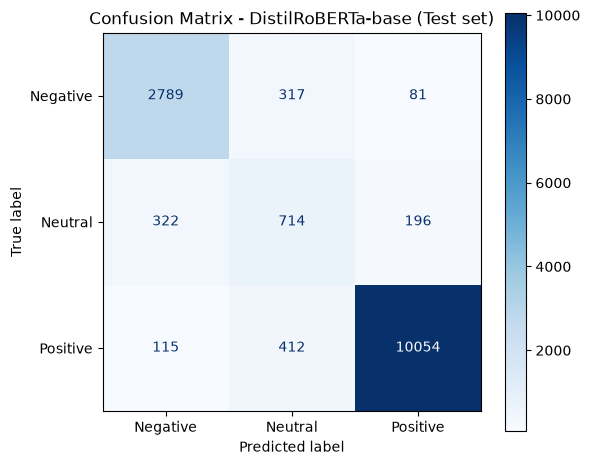

In [ ]:
cm = confusion_matrix(y_test, y_test_pred_distilroberta, labels=CLASS_LABELS)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_LABELS).plot(
    cmap="Blues", ax=ax, colorbar=True, values_format="d"
)
ax.set_title("Confusion Matrix - DistilRoBERTa-base (Test set)")
plt.tight_layout()
plt.show()


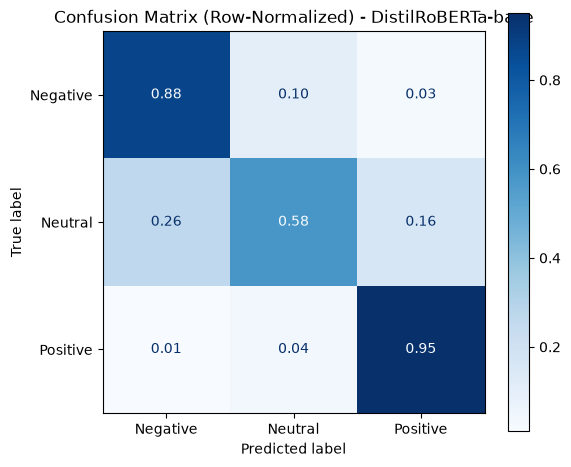

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred_distilroberta, labels=CLASS_LABELS, normalize="true",
    cmap="Blues", ax=ax, values_format=".2f",
)
ax.set_title("Confusion Matrix (Row-Normalized) - DistilRoBERTa-base")
plt.tight_layout()
plt.show()


### 12a. Per-Class Precision / Recall Visualization

The text `classification_report` has the numbers, but a grouped bar chart makes the precision/recall imbalance across classes immediately visible (and easier to compare against the classical-ML notebook's equivalent models at a glance).

In [ ]:
report_dict = classification_report(
    y_test, y_test_pred_distilroberta, labels=CLASS_LABELS, output_dict=True
)

metrics_df = pd.DataFrame({
    label: {"precision": report_dict[label]["precision"],
            "recall": report_dict[label]["recall"],
            "f1-score": report_dict[label]["f1-score"]}
    for label in CLASS_LABELS
}).T

metrics_df.plot(kind="bar", figsize=(8, 4.5), color=["#4C72B0", "#DD8452", "#55A868"])
plt.title("Per-Class Precision / Recall / F1 - DistilRoBERTa-base (Test set)")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


### 12b. Calibration Check (Reliability Diagram)

Unlike `LinearSVC` (which needed `CalibratedClassifierCV` as a Platt-scaling hack) DistilRoBERTa's softmax outputs are genuine probabilities from training -- this is a real advantage worth verifying rather than assuming. A reliability diagram plots predicted confidence against actual accuracy per confidence bucket: perfectly calibrated points sit on the diagonal. We check this one-vs-rest per class.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, label in zip(axes, CLASS_LABELS):
    class_idx = CLASS_LABELS.index(label)
    y_true_binary = (y_test == label).astype(int)
    y_prob_class = test_probs[:, class_idx]

    prob_true, prob_pred = calibration_curve(y_true_binary, y_prob_class, n_bins=10, strategy="quantile")

    ax.plot(prob_pred, prob_true, marker="o", label=label)
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfectly calibrated")
    ax.set_xlabel("Mean predicted probability")
    ax.set_ylabel("Fraction of positives")
    ax.set_title(f"Calibration - {label}")
    ax.legend(fontsize=8)

plt.suptitle("Reliability Diagrams (One-vs-Rest per Class) - DistilRoBERTa-base")
plt.tight_layout()
plt.show()

print("Points above the diagonal = underconfident (true rate higher than predicted); "
      "points below = overconfident (true rate lower than predicted). This directly "
      "informs whether test_probs can be trusted at face value for downstream "
      "business decisions (e.g. flagging low-confidence predictions for human review).")


## 13. Minority-Class Threshold Tuning

DistilRoBERTa outputs real softmax probabilities natively (no calibration
hack needed, unlike LinearSVC in the classical notebook). Same
sweep-and-apply logic as Section 14.3 / 14.3b there: sweep the decision
threshold for the minority class on the validation set, pick the value
that maximizes its F1, then apply it on the held-out test set.

Best threshold for 'Neutral': 0.481 (F1=0.546)


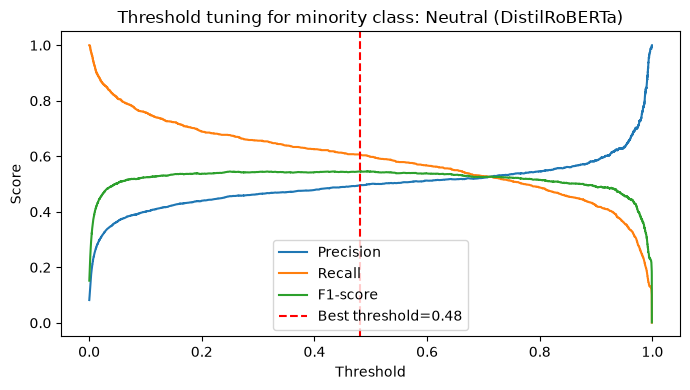

In [ ]:
val_output = trainer.predict(val_ds)
val_probs = torch.softmax(torch.tensor(val_output.predictions), dim=-1).numpy()
minority_idx = CLASS_LABELS.index(MINORITY_CLASS)
val_minority_probs = val_probs[:, minority_idx]
y_val_binary = (y_val == MINORITY_CLASS).astype(int)

precisions, recalls, thresholds = precision_recall_curve(y_val_binary, val_minority_probs)
f1_scores_thresh = 2 * (precisions * recalls) / (precisions + recalls + 1e-12)
best_idx = np.nanargmax(f1_scores_thresh[:-1])
best_threshold = thresholds[best_idx]
print(f"Best threshold for '{MINORITY_CLASS}': {best_threshold:.3f} (F1={f1_scores_thresh[best_idx]:.3f})")

plt.figure(figsize=(7, 4))
plt.plot(thresholds, precisions[:-1], label="Precision")
plt.plot(thresholds, recalls[:-1], label="Recall")
plt.plot(thresholds, f1_scores_thresh[:-1], label="F1-score")
plt.axvline(best_threshold, color="red", linestyle="--", label=f"Best threshold={best_threshold:.2f}")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title(f"Threshold tuning for minority class: {MINORITY_CLASS} (DistilRoBERTa)")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
def predict_with_minority_threshold(probs, minority_class, minority_idx, threshold, class_labels):
    default_pred_ids = np.argmax(probs, axis=-1)
    default_preds = np.array([class_labels[i] for i in default_pred_ids])
    minority_probs = probs[:, minority_idx]
    return np.where(minority_probs >= threshold, minority_class, default_preds)

y_test_pred_tuned_distilroberta = predict_with_minority_threshold(
    test_probs, MINORITY_CLASS, minority_idx, best_threshold, CLASS_LABELS
)

print("Classification Report (Test set) - DistilRoBERTa WITH tuned minority threshold:\n")
print(classification_report(y_test, y_test_pred_tuned_distilroberta, labels=CLASS_LABELS, digits=3))


Classification Report (Test set) - DistilRoBERTa WITH tuned minority threshold:

              precision    recall  f1-score   support

    Negative      0.864     0.874     0.869      3187
     Neutral      0.493     0.581     0.534      1232
    Positive      0.974     0.950     0.962     10581

    accuracy                          0.904     15000
   macro avg      0.777     0.802     0.788     15000
weighted avg      0.911     0.904     0.907     15000



## 13b. Imbalance Strategy Scoreboard: Unweighted vs Balanced vs Dampened

Everything above used `class_weight="balanced"` as a fixed choice, exactly like the classical notebook's early Logistic Regression baseline before Section 15.2 introduced an actual scoreboard. To close that same gap here, we train two additional variants of the loss and compare all three on **validation** macro-F1 and minority-class F1, mirroring the classical notebook's decision process instead of asserting the choice:

1. **Unweighted** (plain `CrossEntropyLoss`, no weighting at all) -- the    null hypothesis this notebook never actually tested.
2. **Balanced** (already trained above as `model`/`trainer` --    `weight(c) = n / (k * n_c)`).
3. **Dampened** (`weight(c) ** 0.5`) -- a middle ground that still    upweights minority classes but less aggressively, which can sometimes    trade a little minority recall for less majority-class damage.

To keep this tractable, the two additional variants below train on a capped subsample (`SCOREBOARD_MAX_SAMPLES`) and for fewer epochs than the primary run -- enough to compare *relative* ranking of strategies, not to replace the fully-trained `model` above. If the scoreboard shows a clear winner other than `balanced`, that's the signal to re-run the primary training cells (Section 9/11) with the winning weighting scheme.

In [ ]:
SCOREBOARD_MAX_SAMPLES = 15000  # capped subsample for a fast, fair 3-way comparison
SCOREBOARD_EPOCHS = 1           # fewer epochs than the primary run - ranking only, not final numbers

_scoreboard_train_df = train_df.sample(
    n=min(SCOREBOARD_MAX_SAMPLES, len(train_df)), random_state=RANDOM_STATE
).reset_index(drop=True)

_scoreboard_train_ds = Dataset.from_pandas(_scoreboard_train_df[["review_transformer", "label"]])
_scoreboard_train_ds = _scoreboard_train_ds.map(
    tokenize_fn, batched=True, num_proc=_num_proc, load_from_cache_file=False
)
assert len(_scoreboard_train_ds) == len(_scoreboard_train_df), "Row count mismatch in scoreboard subsample."

dampened_weights_arr = class_weights_arr ** 0.5
dampened_weights_tensor = torch.tensor(
    [dict(zip(CLASS_LABELS, dampened_weights_arr))[c] for c in CLASS_LABELS], dtype=torch.float
).to(DEVICE)
unweighted_tensor = torch.ones(len(CLASS_LABELS), dtype=torch.float).to(DEVICE)

print("Weight schemes being compared:")
print("  Unweighted:", unweighted_tensor.cpu().numpy().round(3))
print("  Balanced:  ", class_weights_tensor.cpu().numpy().round(3))
print("  Dampened:  ", dampened_weights_tensor.cpu().numpy().round(3))


In [ ]:
class ConfigurableWeightTrainer(Trainer):
    """Same weighted-loss Trainer as WeightedTrainer, but the weight tensor
    is swappable so we can reuse one class for all three strategies."""
    def __init__(self, *args, loss_weight_tensor=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.loss_weight_tensor = loss_weight_tensor

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fct = torch.nn.CrossEntropyLoss(weight=self.loss_weight_tensor)
        loss = loss_fct(logits, labels)
        return (loss, outputs) if return_outputs else loss


def train_scoreboard_variant(weight_tensor, run_name):
    """Fine-tune a fresh model instance for SCOREBOARD_EPOCHS with the given
    loss weight tensor, on the capped subsample, and return val predictions."""
    variant_model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=len(CLASS_LABELS), id2label=id2label, label2id=label2id,
    ).to(DEVICE)

    variant_args = TrainingArguments(
        output_dir=f"./scoreboard_{run_name}",
        eval_strategy="epoch",
        save_strategy="no",
        learning_rate=2e-5,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=32,
        num_train_epochs=SCOREBOARD_EPOCHS,
        weight_decay=0.01,
        logging_steps=100,
        seed=RANDOM_STATE,
        report_to="none",
        fp16=torch.cuda.is_available(),
    )

    variant_trainer = ConfigurableWeightTrainer(
        model=variant_model,
        args=variant_args,
        train_dataset=_scoreboard_train_ds,
        eval_dataset=val_ds,
        processing_class=tokenizer,
        data_collator=data_collator,
        loss_weight_tensor=weight_tensor,
    )
    variant_trainer.train()

    val_out = variant_trainer.predict(val_ds)
    val_pred_ids = np.argmax(val_out.predictions, axis=-1)
    return np.array([CLASS_LABELS[i] for i in val_pred_ids])

print("Training UNWEIGHTED variant...")
y_val_pred_unweighted = train_scoreboard_variant(unweighted_tensor, "unweighted")

print("Training DAMPENED variant...")
y_val_pred_dampened = train_scoreboard_variant(dampened_weights_tensor, "dampened")

# Balanced variant: reuse the primary model already trained in Section 11
# rather than retraining, since it is identical to what "balanced" would give.
val_output_balanced = trainer.predict(val_ds)
y_val_pred_balanced = np.array(
    [CLASS_LABELS[i] for i in np.argmax(val_output_balanced.predictions, axis=-1)]
)


In [ ]:
# ---------------------------------------------------------------------------
# Score all three strategies on validation macro-F1 and minority-class F1
# ---------------------------------------------------------------------------
imbalance_scoreboard = []
for name, preds in [
    ("unweighted", y_val_pred_unweighted),
    ("balanced (primary run)", y_val_pred_balanced),
    ("dampened (sqrt)", y_val_pred_dampened),
]:
    imbalance_scoreboard.append({
        "strategy": name,
        "macro_f1": f1_score(y_val, preds, labels=CLASS_LABELS, average="macro"),
        f"{MINORITY_CLASS}_f1": f1_score(y_val, preds, labels=[MINORITY_CLASS], average="macro"),
        "accuracy": (preds == y_val.values).mean(),
    })

imbalance_scoreboard_df = pd.DataFrame(imbalance_scoreboard).sort_values("macro_f1", ascending=False).reset_index(drop=True)
print(imbalance_scoreboard_df)

winner = imbalance_scoreboard_df.loc[0, "strategy"]
print(f"\nScoreboard winner: {winner}")
if winner != "balanced (primary run)":
    print(f"NOTE: '{winner}' outperformed the balanced weighting used in the primary "
          f"run above (Sections 9-13). Consider re-running Section 9/11 with that "
          f"weighting scheme for the final reported numbers, since everything "
          f"downstream (threshold tuning, master results) currently reflects "
          f"'balanced' only.")
else:
    print("The balanced weighting used throughout this notebook is empirically "
          "confirmed as the best of the three strategies on validation data - "
          "no change needed to the primary run.")


## 14. Output Format - Master Results Table

Identical schema to `master_results` / `master_df` from the classical-ML
notebook (Section 16), so this can be concatenated directly with that
notebook's `master_df` for a full 4-way (LR / SVC / NB / DistilRoBERTa)
comparison.

In [ ]:
master_results_distilroberta = []

def add_result(name, y_true, y_pred):
    master_results_distilroberta.append({
        "model": name,
        "accuracy": (np.array(y_pred) == np.array(y_true)).mean(),
        "macro_f1": f1_score(y_true, y_pred, labels=CLASS_LABELS, average="macro"),
        "weighted_f1": f1_score(y_true, y_pred, labels=CLASS_LABELS, average="weighted"),
        f"{MINORITY_CLASS}_f1": f1_score(y_true, y_pred, labels=[MINORITY_CLASS], average="macro"),
    })

add_result("DistilRoBERTa - baseline (class-weighted loss)", y_test, y_test_pred_distilroberta)
add_result("DistilRoBERTa - tuned threshold", y_test, y_test_pred_tuned_distilroberta)

master_df_distilroberta = (
    pd.DataFrame(master_results_distilroberta)
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)
master_df_distilroberta


,model,accuracy,macro_f1,weighted_f1,Neutral_f1
0,DistilRoBERTa - baseline (class-weighted loss),0.903800,0.788394,0.906928,0.533832
1,DistilRoBERTa - tuned threshold,0.903667,0.788271,0.906904,0.533731


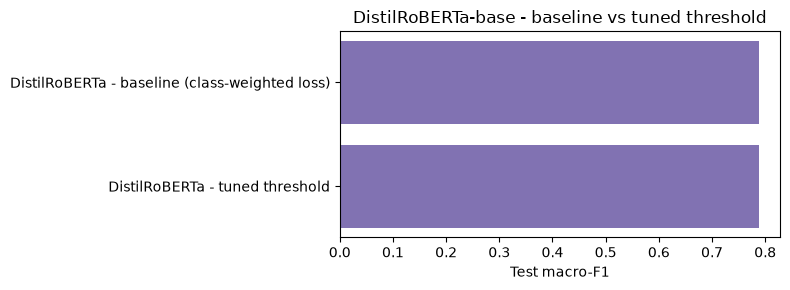

In [ ]:
plt.figure(figsize=(8, 3))
order = master_df_distilroberta.sort_values("macro_f1")
plt.barh(order["model"], order["macro_f1"], color="#8172B2")
plt.xlabel("Test macro-F1")
plt.title("DistilRoBERTa-base - baseline vs tuned threshold")
plt.tight_layout()
plt.show()


## 15. Save Results for Cross-Notebook Comparison

Persists everything needed to merge into the classical-ML notebook's
Section 16 / 16b master comparison without re-running training.

In [ ]:
master_df_distilroberta.to_csv("distilroberta_master_results.csv", index=False)
np.save("y_test_pred_distilroberta.npy", y_test_pred_distilroberta)
np.save("y_test_pred_tuned_distilroberta.npy", y_test_pred_tuned_distilroberta)
test_df[["review", "sentiment_3class"]].assign(
    pred_baseline=y_test_pred_distilroberta,
    pred_tuned=y_test_pred_tuned_distilroberta,
).to_csv("distilroberta_test_predictions.csv", index=False)

print(
    "Saved: distilroberta_master_results.csv, y_test_pred_distilroberta.npy, "
    "y_test_pred_tuned_distilroberta.npy, distilroberta_test_predictions.csv\n\n"
    "To merge with the classical-ML notebook's Section 16 comparison, run there:\n"
    "  distil_df = pd.read_csv('distilroberta_master_results.csv')\n"
    "  master_df_full = pd.concat([master_df, distil_df], ignore_index=True)"
)


Saved: distilroberta_master_results.csv, y_test_pred_distilroberta.npy, y_test_pred_tuned_distilroberta.npy, distilroberta_test_predictions.csv

To merge with the classical-ML notebook's Section 16 comparison, run there:
  distil_df = pd.read_csv('distilroberta_master_results.csv')
  master_df_full = pd.concat([master_df, distil_df], ignore_index=True)
